# 04. Aeroportos críticos

Este notebook responde à pergunta principal do projeto:

> Quais aeroportos brasileiros, se fechados, mais desconectam a malha doméstica ou mais aumentam o número de escalas entre as capitais? Os aeroportos mais conectados (hubs) são os mesmos que os mais críticos como ponte?

No notebook 03, os aeroportos eram fechados em sequência, até a rede inteira cair. Aqui o cenário é o realista: **um aeroporto fecha sozinho** (por alagamento, nevoeiro ou falha), e todos os outros continuam operando. Repetimos isso para cada um dos 154 aeroportos da malha de abril/2024.

**Conteúdo do curso usado neste notebook**

| Conceito | Semana | Seção |
|---|---|---|
| Componentes (SCC) | 4 | 1 e 2 |
| Eficiência | 4 | 1, 2 e 4 |
| BFS, caminhos e distâncias | 3 e 4 | 3 e 5 |
| Grau, betweenness | 2 e 4 | 4 |
| k-core | 5 | 2 e 4 |

In [1]:
import sys
from pathlib import Path
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(raiz / "src"))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

from fechamentos import impacto_individual
from metricas import (analise_kcore, calcular_centralidades, escalas_bfs_origem,
                      escalas_entre_capitais, tabela_graus)
from rede import CAPITAIS, carregar_grafo, nome_curto

PASTA_FIG = raiz / "figures"
PASTA_FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 2)

G_ref = carregar_grafo(raiz / "data" / "processed" / "rede_referencia.graphml")
print(f"Malha de referência (abril/2024): {G_ref.number_of_nodes()} aeroportos e {G_ref.number_of_edges()} rotas.")

Malha de referência (abril/2024): 154 aeroportos e 816 rotas.


## 1. Método: fechar cada aeroporto sozinho

Para cada aeroporto fechado, comparamos a rede com a malha intacta em quatro medidas (função `impacto_individual` em `src/fechamentos.py`):

| Medida | O que responde |
|---|---|
| perda de eficiência (%) | quanto os caminhos da malha como um todo ficam mais longos ou deixam de existir |
| aeroportos fora da SCC | quantos outros aeroportos perdem a ida e volta com o resto da malha |
| pares de capitais sem caminho | se alguma capital deixa de alcançar outra |
| pares de capitais com mais escalas | quantas ligações entre capitais passam a exigir mais escalas |

As medidas entre capitais consideram só as capitais que continuam com aeroporto. Fechar o único aeroporto de uma capital tira a própria capital da malha, o que é registrado à parte, na coluna "capital sem aeroporto".

In [2]:
impacto = impacto_individual(G_ref, CAPITAIS)
impacto = (impacto
           .join(tabela_graus(G_ref)["grau total"])
           .join(calcular_centralidades(G_ref)["betweenness"])
           .join(analise_kcore(G_ref)["core_number"]))
impacto.insert(0, "nome", [nome_curto(G_ref, n) for n in impacto.index])
for medida in ["perda de eficiência (%)", "grau total", "betweenness"]:
    impacto[f"posição {medida.split(' (')[0]}"] = impacto[medida].rank(ascending=False, method="min").astype(int)

print(f"aeroportos simulados: {len(impacto)}")
print(f"fechamentos que deixam algum par de capitais sem caminho: {(impacto['pares de capitais sem caminho'] > 0).sum()}")
print(f"fechamentos que aumentam escalas entre capitais: {(impacto['pares de capitais com mais escalas'] > 0).sum()}")
print(f"fechamentos que tiram algum aeroporto da maior SCC: {(impacto['aeroportos fora da SCC'] > 0).sum()}")
print("\nperda de eficiência (%) nos 154 fechamentos:")
print(impacto["perda de eficiência (%)"].describe().round(2).to_string())

aeroportos simulados: 154
fechamentos que deixam algum par de capitais sem caminho: 0
fechamentos que aumentam escalas entre capitais: 3
fechamentos que tiram algum aeroporto da maior SCC: 28

perda de eficiência (%) nos 154 fechamentos:
count    154.00
mean       1.90
std        2.37
min        0.57
25%        1.14
50%        1.31
75%        1.47
max       16.25


- **Nenhum fechamento isolado deixa duas capitais sem caminho entre si.** A malha entre capitais é redundante o bastante para absorver a perda de qualquer aeroporto.
- **Só 3 dos 154 fechamentos aumentam as escalas entre capitais.** Para os outros 151, todas as ligações entre capitais continuam com o mesmo número de escalas.
- **28 fechamentos tiram algum aeroporto da maior SCC.** É aqui que a malha se desconecta: não entre capitais, mas entre os aeroportos regionais e o resto do país.
- A perda de eficiência é pequena para quase todos (mediana de 1,3%), mas chega a **16%** no pior caso. Poucos aeroportos concentram o dano.

## 2. Quem mais desconecta a malha

In [3]:
colunas = ["nome", "perda de eficiência (%)", "aeroportos fora da SCC", "grau total", "posição grau total",
           "posição betweenness", "core_number"]
impacto.sort_values("perda de eficiência (%)", ascending=False)[colunas].head(12)

,nome,perda de eficiência (%),aeroportos fora da SCC,grau total,posição grau total,posição betweenness,core_number
aeroporto,,,,,,,
SBCF,Tancredo Neves (MG),16.25,12,102,3,2,9
SBEG,Eduardo Gomes (AM),15.07,13,45,8,3,7
SBKP,Viracopos (SP),13.63,10,112,1,1,9
SBRF,Guararapes (PE),11.48,8,72,5,5,9
SBBE,Val de Cans (PA),10.22,8,45,8,6,8
SBCY,Marechal Rondon (MT),8.61,7,34,14,7,8
SBPA,Salgado Filho (RS),8.10,6,40,10,9,8
SBCT,Afonso Pena (PR),6.94,5,38,12,11,8
SBFZ,Pinto Martins (CE),5.35,3,39,11,12,9


In [4]:
scc_intacta = max(nx.strongly_connected_components(G_ref), key=len)
for icao in ["SBEG", "SBCF", "SBKP"]:
    H = G_ref.copy()
    H.remove_node(icao)
    perdidos = scc_intacta - max(nx.strongly_connected_components(H), key=len) - {icao}
    print(f"fechar {nome_curto(G_ref, icao)} tira {len(perdidos)} aeroportos da maior SCC:")
    print("   " + ", ".join(sorted(nome_curto(G_ref, n) for n in perdidos)))

fechar Eduardo Gomes (AM) tira 13 aeroportos da maior SCC:
   Barcelos (AM), Borba (AM), Coari (AM), Eirunepé (AM), Júlio Bélem (AM), Lábrea (AM), Manicoré (AM), Maués (AM), Prainha (AM), Santa Izabel do Rio Negro (AM), São Gabriel da Cachoeira (AM), Tabatinga (AM), Tefé (AM)
fechar Tancredo Neves (MG) tira 12 aeroportos da maior SCC:
   Aeroporto Elias Breder (MG), Aeródromo Municipal de Linhares (ES), Barreiras (BA), Cabo Frio (RJ), Coronel Altino Machado (MG), Guanambi (BA), Horácio de Mattos (BA), Juscelino Kubitscheck (MG), Major Brigadeiro Trompowsky (MG), Paracatu (MG), Patos de Minas (MG), Salinas (MG)
fechar Viracopos (SP) tira 10 aeroportos da maior SCC:
   Aeroporto Estadual de Bauru-Arealva / Moussa Nakhl Tobias (SP), Aeroporto Regional do Planalto Serrano (SC), Bartolomeu Lisandro (RJ), Comandante Antonio Amilton Beraldo (PR), Corumbá (MS), Frank Miloye Milenkovich (SP), Ponta Porã (MS), Rondonópolis (MT), Tancredo Thomas de Faria (PR), Três Lagoas (MS)


- Os sete aeroportos que mais desconectam a malha são **Confins (16% de eficiência, 12 aeroportos fora da SCC), Manaus (15%, 13), Viracopos (14%, 10), Recife (11%, 8), Belém (10%, 8), Cuiabá (9%, 7) e Porto Alegre (8%, 6)**.
- Cada um deles é a **única porta de entrada de uma sub-rede regional**:
  - **Manaus**: os 13 aeroportos que perdem a ligação são todos do interior do Amazonas (Tabatinga, Tefé, Coari, São Gabriel da Cachoeira…), que só se ligam ao resto do país por Manaus;
  - **Confins**: aeroportos regionais de Minas Gerais e do interior da Bahia, além de Cabo Frio e Linhares;
  - **Viracopos**: o interior de Mato Grosso do Sul, do Paraná e de São Paulo, que a Azul liga ao país por Campinas.
- Porto Alegre aparece em 7º lugar, com 6 aeroportos dependentes. O fechamento real de maio de 2024 atingiu, portanto, **um dos aeroportos mais críticos da malha**, o que será comparado com o que de fato aconteceu no notebook de POA.
- Todos os sete estão no núcleo ou na sua borda (k = 7 a 9) e entre os 9 maiores em betweenness.

## 3. Quem mais aumenta as escalas entre capitais

In [5]:
colunas_cap = ["nome", "capital sem aeroporto", "pares de capitais sem caminho",
               "pares de capitais com mais escalas", "escalas a mais entre capitais", "grau total"]
impacto[impacto["pares de capitais com mais escalas"] > 0].sort_values(
    "pares de capitais com mais escalas", ascending=False)[colunas_cap]

,nome,capital sem aeroporto,pares de capitais sem caminho,pares de capitais com mais escalas,escalas a mais entre capitais,grau total
aeroporto,,,,,,
SBBR,Brasília (DF),Brasília,0,65,65.0,72
SBGL,Galeão (RJ),,0,26,26.0,46
SBGR,Guarulhos (SP),,0,12,12.0,104


In [6]:
escalas_intacta = escalas_entre_capitais(G_ref, CAPITAIS)

def capitais_sem(icao):
    """Escalas entre capitais com `icao` fechado e as capitais mais afetadas."""
    H = G_ref.copy()
    H.remove_node(icao)
    restantes = {c: [a for a in aer if a != icao] for c, aer in CAPITAIS.items()}
    restantes = {c: aer for c, aer in restantes.items() if aer}
    depois = escalas_entre_capitais(H, restantes)
    aumento = (depois - escalas_intacta.loc[list(restantes), list(restantes)]).stack().dropna()
    aumento = aumento[aumento > 0]
    envolvidas = pd.concat([aumento.index.to_frame()[0], aumento.index.to_frame()[1]]).value_counts()
    return depois, aumento, envolvidas

for icao in ["SBBR", "SBGL", "SBGR"]:
    depois, aumento, envolvidas = capitais_sem(icao)
    print(f"{nome_curto(G_ref, icao)} fechado: {len(aumento)} pares com mais escalas; "
          f"máximo de escalas entre capitais: {depois.max().max():.0f}")
    print(f"   capitais mais envolvidas: {envolvidas.head(4).to_dict()}")

Brasília (DF) fechado: 65 pares com mais escalas; máximo de escalas entre capitais: 2
   capitais mais envolvidas: {'Rio Branco': 36, 'Macapá': 29, 'Porto Velho': 6, 'Maceió': 4}


Galeão (RJ) fechado: 26 pares com mais escalas; máximo de escalas entre capitais: 1
   capitais mais envolvidas: {'Rio de Janeiro': 26, 'Maceió': 2, 'Manaus': 2, 'Salvador': 2}


Guarulhos (SP) fechado: 12 pares com mais escalas; máximo de escalas entre capitais: 1
   capitais mais envolvidas: {'São Paulo': 12, 'Manaus': 2, 'São Luís': 2, 'Belém': 2}


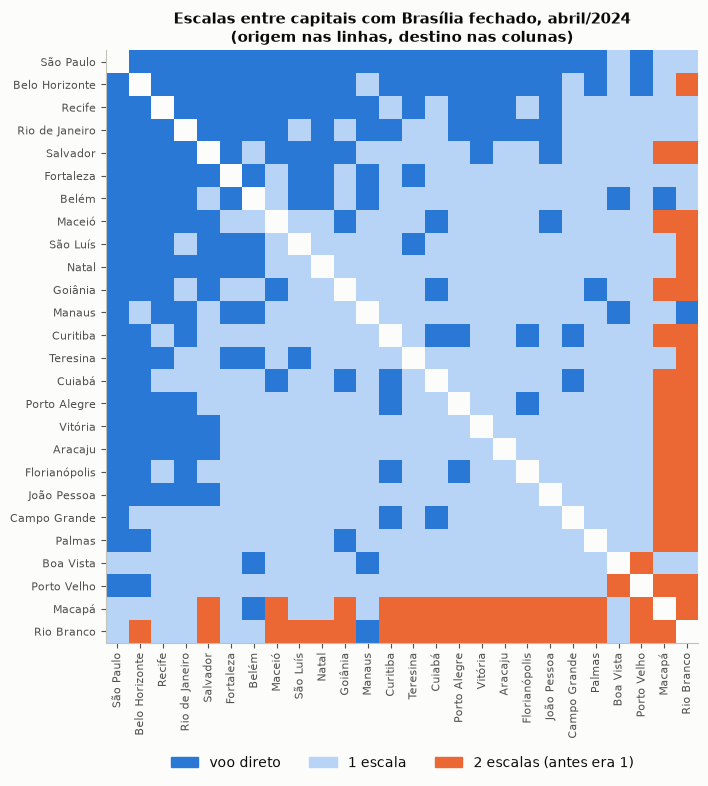

In [7]:
depois, aumento, _ = capitais_sem("SBBR")
ordem = escalas_intacta.drop(index="Brasília", columns="Brasília").mean(axis=1).sort_values().index
M = depois.loc[ordem, ordem]

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
cores = ["#2a78d6", "#b7d3f6", "#eb6834"]
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(M.values, cmap=ListedColormap(cores), vmin=0, vmax=2, interpolation="nearest")
ax.grid(False)
ax.set_xticks(range(len(ordem)), ordem, rotation=90, fontsize=8)
ax.set_yticks(range(len(ordem)), ordem, fontsize=8)
ax.legend(handles=[Patch(color=cores[0], label="voo direto"), Patch(color=cores[1], label="1 escala"),
                   Patch(color=cores[2], label="2 escalas (antes era 1)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
ax.set_title("Escalas entre capitais com Brasília fechado, abril/2024\n(origem nas linhas, destino nas colunas)")
fig.tight_layout()
fig.savefig(PASTA_FIG / "04_capitais_sem_brasilia.png", dpi=150)
plt.show()

- **Brasília** é, de longe, o fechamento que mais afeta as capitais: **65 pares** (origem, destino) passam de 1 para 2 escalas. Quase todos envolvem **Rio Branco (36 pares) e Macapá (29)**: essas capitais têm voo direto para só duas capitais, uma delas Brasília (notebook 02), e sem ela passam a precisar de duas conexões para chegar à maior parte do país.
- **Galeão (26 pares)** e **Guarulhos (12 pares)** vêm depois. Nos dois casos, todos os pares afetados têm a própria cidade como origem ou destino: o Rio continua com o Santos Dumont, e São Paulo com Congonhas, mas esses aeroportos não têm voo direto para algumas capitais que o Galeão e Guarulhos atendiam.
- Nenhum fechamento leva duas capitais a mais de 2 escalas.

Figura salva em `figures/04_capitais_sem_brasilia.png`.

## 4. Hubs são as mesmas pontes?

In [8]:
top = lambda coluna: set(impacto[coluna].nlargest(10).index)
comparacao = pd.DataFrame({
    "em comum com o top 10 de grau": {m: len(top(m) & top("grau total")) for m in ["perda de eficiência (%)", "aeroportos fora da SCC"]},
    "em comum com o top 10 de betweenness": {m: len(top(m) & top("betweenness")) for m in ["perda de eficiência (%)", "aeroportos fora da SCC"]},
})
comparacao.index.name = "top 10 de dano por"
display(comparacao)

hubs = impacto.nsmallest(10, "posição grau total")
print("os 10 maiores em grau e o dano que causam ao fechar:")
hubs[["nome", "grau total", "perda de eficiência (%)", "posição perda de eficiência",
      "aeroportos fora da SCC", "pares de capitais com mais escalas"]]

,em comum com o top 10 de grau,em comum com o top 10 de betweenness
top 10 de dano por,,
perda de eficiência (%),7,8
aeroportos fora da SCC,6,7


os 10 maiores em grau e o dano que causam ao fechar:


,nome,grau total,perda de eficiência (%),posição perda de eficiência,aeroportos fora da SCC,pares de capitais com mais escalas
aeroporto,,,,,,
SBKP,Viracopos (SP),112,13.63,3,10,0
SBGR,Guarulhos (SP),104,3.11,11,0,12
SBCF,Tancredo Neves (MG),102,16.25,1,12,0
SBSP,Congonhas (SP),80,3.35,10,1,0
SBBR,Brasília (DF),72,2.56,13,0,65
SBRF,Guararapes (PE),72,11.48,4,8,0
SBGL,Galeão (RJ),46,2.98,12,1,26
SBBE,Val de Cans (PA),45,10.22,5,8,0
SBEG,Eduardo Gomes (AM),45,15.07,2,13,0


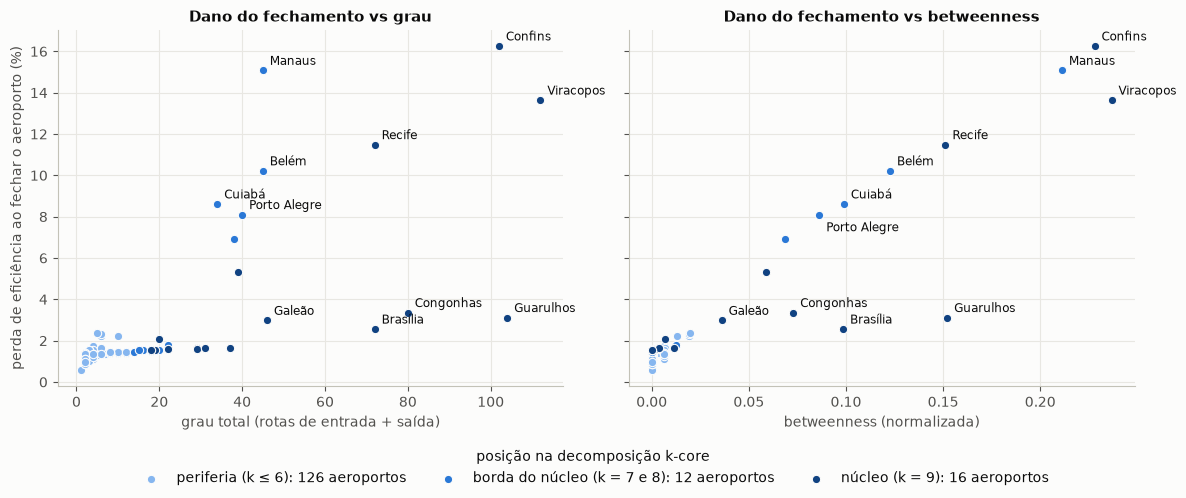

In [9]:
grupos = [
    ("periferia (k ≤ 6)", impacto["core_number"] <= 6, "#86b6ef"),
    ("borda do núcleo (k = 7 e 8)", impacto["core_number"].between(7, 8), "#2a78d6"),
    (f"núcleo (k = {impacto['core_number'].max()})", impacto["core_number"] == impacto["core_number"].max(), "#104281"),
]
rotulos = {"SBCF": "Confins", "SBEG": "Manaus", "SBKP": "Viracopos", "SBRF": "Recife", "SBBE": "Belém",
           "SBCY": "Cuiabá", "SBPA": "Porto Alegre", "SBGR": "Guarulhos", "SBSP": "Congonhas",
           "SBBR": "Brasília", "SBGL": "Galeão"}

fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, x, xlabel in [(eixos[0], "grau total", "grau total (rotas de entrada + saída)"),
                      (eixos[1], "betweenness", "betweenness (normalizada)")]:
    for rotulo, filtro, cor in grupos:
        d = impacto[filtro]
        ax.scatter(d[x], d["perda de eficiência (%)"], s=36, color=cor, edgecolor="#fcfcfb", linewidth=0.8,
                   label=f"{rotulo}: {filtro.sum()} aeroportos")
    for icao, texto in rotulos.items():
        deslocamento = (5, -12) if (icao == "SBPA" and x == "betweenness") else (5, 4)
        ax.annotate(texto, (impacto.loc[icao, x], impacto.loc[icao, "perda de eficiência (%)"]),
                    xytext=deslocamento, textcoords="offset points", fontsize=8.5, color="#0b0b0b")
    ax.set(xlabel=xlabel)
eixos[0].set_ylabel("perda de eficiência ao fechar o aeroporto (%)")
eixos[0].set_title("Dano do fechamento vs grau")
eixos[1].set_title("Dano do fechamento vs betweenness")
handles, labels = eixos[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, title="posição na decomposição k-core")
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(PASTA_FIG / "04_dano_vs_centralidade.png", dpi=150)
plt.show()

- **Entre os 10 maiores em grau, 4 causam pouco dano ao fechar:** Guarulhos (2º em grau), Congonhas (4º), Brasília (5º) e Galeão (7º) tiram só 2,6% a 3,4% da eficiência e no máximo 1 aeroporto da maior SCC. São hubs **redundantes**: estão no núcleo (k = 9), e seus vizinhos têm alternativas, sobretudo em São Paulo e no Rio, que têm mais de um aeroporto.
- **A betweenness prevê o dano melhor que o grau.** O top 10 de perda de eficiência tem 8 aeroportos em comum com o top 10 de betweenness e 7 com o de grau. No gráfico, o dano cresce quase em linha com a betweenness; as exceções são justamente Guarulhos e Brasília.
- **Há dois tipos diferentes de aeroporto crítico:**
  1. **Portas regionais** (Confins, Manaus, Viracopos, Recife, Belém, Cuiabá, Porto Alegre): fechar um deles **desconecta a periferia** que depende dele. Têm betweenness alta e ficam no núcleo ou na sua borda.
  2. **Conectores nacionais** (Brasília, Galeão, Guarulhos): fechar um deles **não desconecta quase nada**, mas **aumenta as escalas entre capitais**, porque eles têm as ligações diretas que outras capitais não têm.

  Os dois grupos não se sobrepõem: nenhum aeroporto está entre os piores nas duas dimensões.

Figura salva em `figures/04_dano_vs_centralidade.png`.

## 5. O caso de Natal

In [10]:
base = escalas_bfs_origem(G_ref, "SBSG").set_index("destino")["escalas"]
capitais_natal = {c: a for c, a in CAPITAIS.items() if c != "Natal"}

linhas = []
for icao in impacto.index.drop("SBSG"):
    H = G_ref.copy()
    H.remove_node(icao)
    depois = escalas_bfs_origem(H, "SBSG").set_index("destino")["escalas"]
    comum = depois.index.intersection(base.index)
    restantes = {c: [a for a in aer if a != icao] for c, aer in capitais_natal.items()}
    caps_antes = {c: min(base[a] for a in aer) for c, aer in capitais_natal.items()}
    caps_depois = {c: min((depois[a] for a in aer if a in depois), default=np.nan) for c, aer in restantes.items() if aer}
    linhas.append({
        "aeroporto fechado": nome_curto(G_ref, icao),
        "aeroportos inalcançáveis a partir de Natal": len(base) - 1 - len(depois),
        "aeroportos com mais escalas": int((depois[comum] > base[comum]).sum()),
        "capitais com mais escalas": [c for c, e in caps_depois.items() if e > caps_antes[c]],
    })
natal = pd.DataFrame(linhas).set_index("aeroporto fechado")
natal = natal.sort_values(["aeroportos inalcançáveis a partir de Natal", "aeroportos com mais escalas"], ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(natal.head(10))
    display(natal[natal["capitais com mais escalas"].str.len() > 0])

,aeroportos inalcançáveis a partir de Natal,aeroportos com mais escalas,capitais com mais escalas
aeroporto fechado,,,
Eduardo Gomes (AM),13,0,[]
Tancredo Neves (MG),12,0,[]
Viracopos (SP),9,1,[]
Guararapes (PE),8,1,[]
Val de Cans (PA),8,0,[]
Marechal Rondon (MT),7,0,[]
Salgado Filho (RS),6,0,[]
Afonso Pena (PR),5,0,[]
Pinto Martins (CE),4,0,[]


,aeroportos inalcançáveis a partir de Natal,aeroportos com mais escalas,capitais com mais escalas
aeroporto fechado,,,
Galeão (RJ),1,0,[Rio de Janeiro]
Brasília (DF),0,2,[Rio Branco]


- **Nenhum fechamento isolado deixa Natal sem ligação com alguma capital**, e no máximo uma capital passa a exigir uma escala a mais: Rio Branco, se Brasília fechar, ou o Rio de Janeiro, se o Galeão fechar (o Santos Dumont não tem voo direto para Natal).
- O efeito sobre Natal aparece no interior do país: com Manaus fechado, **13 aeroportos ficam inalcançáveis a partir de Natal**; com Confins, 12; com Viracopos, 9.
- Para quem sai de Natal, portanto, o risco não é perder as capitais, mas perder o acesso às regiões que dependem de uma única porta regional.

## Resposta à pergunta principal

**Quais aeroportos, se fechados, mais desconectam a malha?** As portas regionais: **Confins, Manaus, Viracopos, Recife, Belém, Cuiabá e Porto Alegre**. Cada uma é o único acesso de uma sub-rede de 6 a 13 aeroportos ao resto do país.

**Quais mais aumentam as escalas entre capitais?** Só três: **Brasília** (65 pares de capitais com +1 escala, sobretudo Rio Branco e Macapá), **Galeão** (26) e **Guarulhos** (12). Nenhum fechamento isolado deixa capitais sem caminho.

**Os hubs são as mesmas pontes?** **Em parte.** Grau e betweenness concordam sobre quem são os grandes, mas o grau sozinho engana: Guarulhos, Congonhas, Brasília e Galeão estão entre os 7 maiores em grau e quase não desconectam a malha. A betweenness acompanha melhor o dano. E a criticidade tem dois tipos: os aeroportos que desconectam a periferia não são os mesmos que alongam as viagens entre capitais.

**Próximo passo:** comparar a simulação do fechamento de Porto Alegre com a malha real de maio e junho de 2024 (H4).